In [ ]:
!pip install pennylane

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 45.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 45.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 86.0 MB/s eta 0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1


--- [KOD 4] KLASİK k-NN VE QKNN DENEYLERİ BAŞLATILIYOR ---
Toplam Örneklem: 200 (Fraud: 100, Normal: 100)
Eğitim Seti: 160 | Test Seti: 40

PCA İlk 4 Bileşenin Açıkladığı Varyans Oranları: [0.3897 0.0988 0.0828 0.0717]
Toplam Açıklanan Varyans: %64.29

--- [YÖNTEM 1] Klasik k-NN Çalıştırılıyor ---
--- [YÖNTEM 2] QKNN (Adjoint Kernel) Çalıştırılıyor ---
   -> Adjoint Mesafe Matrisi: 40/160 satır tamamlandı.
   -> Adjoint Mesafe Matrisi: 80/160 satır tamamlandı.
   -> Adjoint Mesafe Matrisi: 120/160 satır tamamlandı.
   -> Adjoint Mesafe Matrisi: 160/160 satır tamamlandı.
   -> Adjoint Mesafe Matrisi: 40/40 satır tamamlandı.

--- [YÖNTEM 3] QKNN (Swap Test Devresi - 9 Kübit) Çalıştırılıyor ---
   -> Swap Mesafe Matrisi: 40/160 satır tamamlandı.
   -> Swap Mesafe Matrisi: 80/160 satır tamamlandı.
   -> Swap Mesafe Matrisi: 120/160 satır tamamlandı.
   -> Swap Mesafe Matrisi: 160/160 satır tamamlandı.
   -> Swap Mesafe Matrisi: 40/40 satır tamamlandı.

--- 5-FOLD ÇAPRAZ DOĞRULAMA HESAPLANI

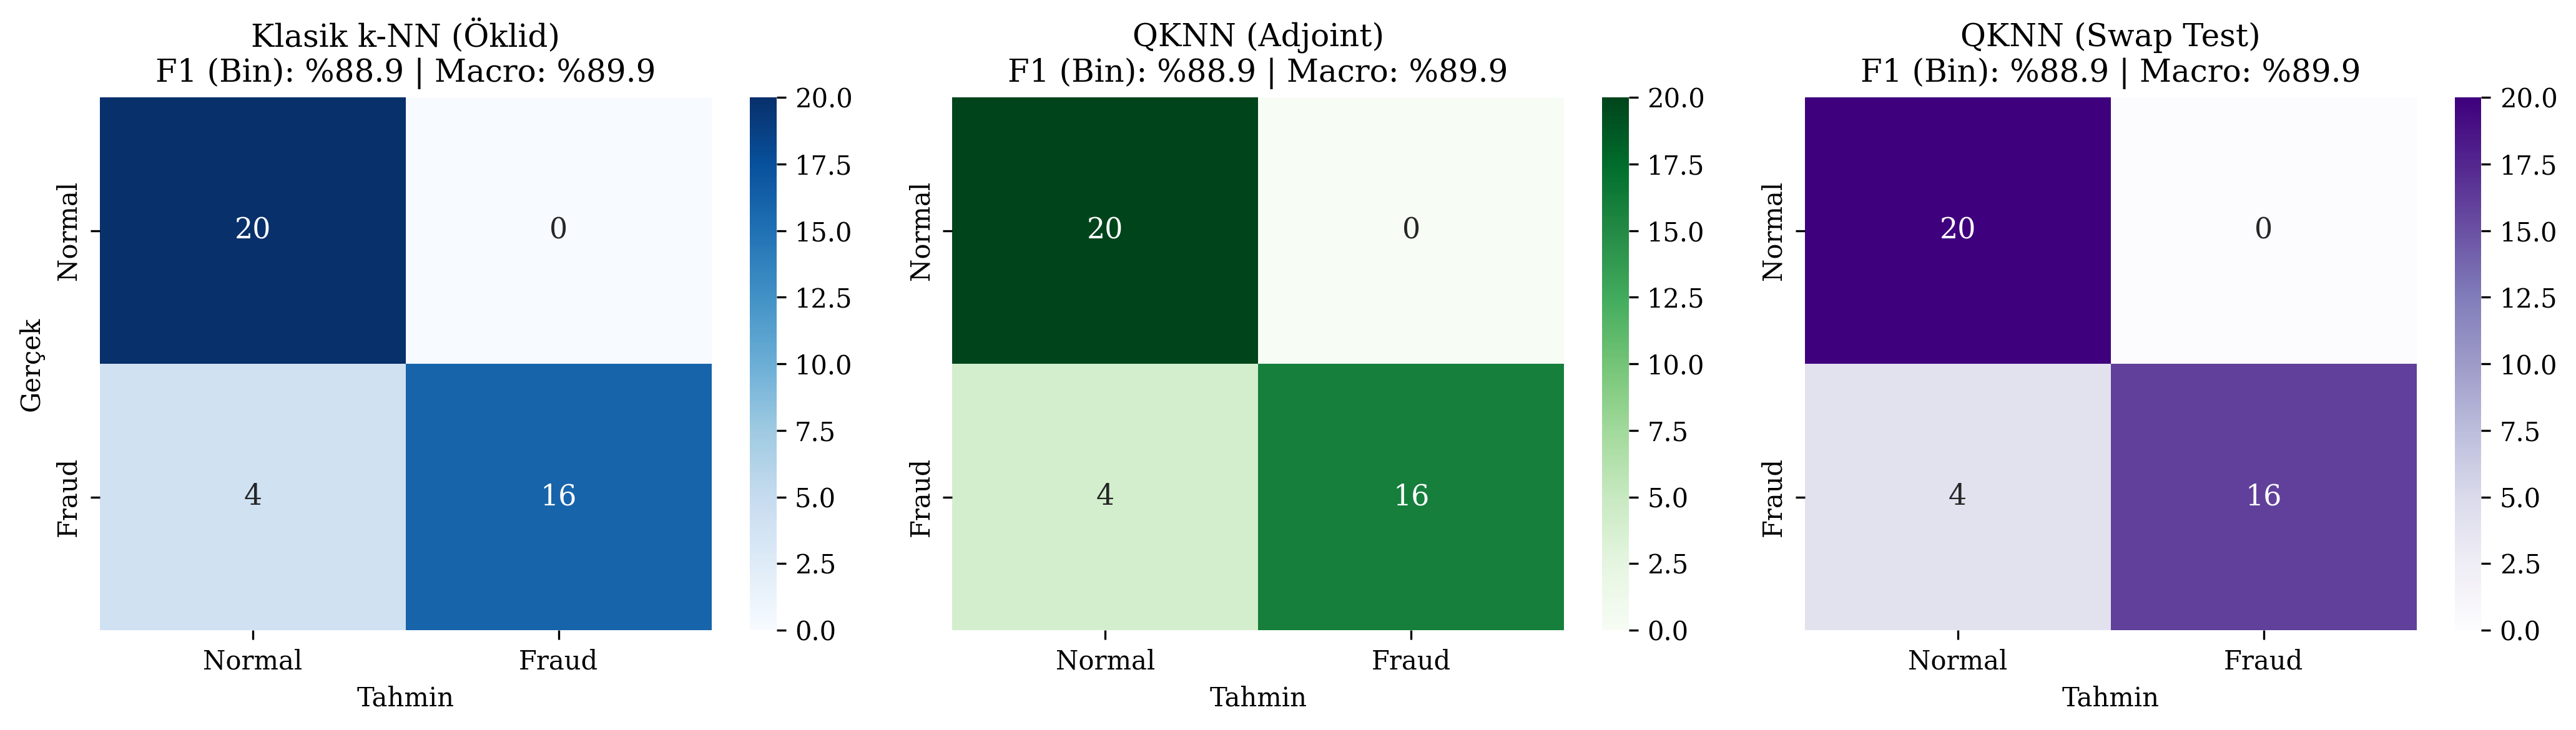

In [ ]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# ==========================================================
# 1. VERİ HAZIRLIĞI VE ÖRNEKLEME PROTOKOLÜ (HAKEM #2 YORUM #2)
# ==========================================================
print("--- [KOD 4] KLASİK k-NN VE QKNN DENEYLERİ BAŞLATILIYOR ---")
df = pd.read_csv("creditcard.csv")

RANDOM_SEED = 42
n_samples_per_class = 100

fraud = df[df["Class"] == 1].sample(n=n_samples_per_class, random_state=RANDOM_SEED)
normal = df[df["Class"] == 0].sample(n=n_samples_per_class, random_state=RANDOM_SEED)
df_balanced = (
    pd.concat([fraud, normal])
    .sample(frac=1, random_state=RANDOM_SEED)
    .reset_index(drop=True)
)

cols_to_drop = [col for col in ["Time", "Class"] if col in df_balanced.columns]
X_raw = df_balanced.drop(columns=cols_to_drop).values
y = df_balanced["Class"].values

print(f"Toplam Örneklem: {len(X_raw)} (Fraud: {np.sum(y == 1)}, Normal: {np.sum(y == 0)})")

# ==========================================================
# 2. VERİ BÖLME VE VERİ SIZINTISINI ÖNLEME (HAKEM #2 YORUM #3)
# ==========================================================
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)
print(f"Eğitim Seti: {len(X_train_raw)} | Test Seti: {len(X_test_raw)}\n")

# A) Standardizasyon (Yalnızca train üzerinde fit)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

# B) PCA 4 Boyut (Yalnızca train üzerinde fit)
n_qubits = 4
pca_4d = PCA(n_components=n_qubits, random_state=RANDOM_SEED)
X_train_4d = pca_4d.fit_transform(X_train_scaled)
X_test_4d = pca_4d.transform(X_test_scaled)

explained_variance = pca_4d.explained_variance_ratio_
total_var = np.sum(explained_variance) * 100
print(f"PCA İlk 4 Bileşenin Açıkladığı Varyans Oranları: {np.round(explained_variance, 4)}")
print(f"Toplam Açıklanan Varyans: %{total_var:.2f}\n")

# C) Kuantum Açısal Kodlama Normalizasyonu [-pi, pi] (Yalnızca train üzerinde fit)
minmax_scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))
X_train_angles = minmax_scaler.fit_transform(X_train_4d)
X_test_angles = minmax_scaler.transform(X_test_4d)

k_neighbors = 5

# ==========================================================
# 3. YÖNTEM 1: KLASİK k-NN (ÖKLİD MESAFESİ)
# ==========================================================
print("--- [YÖNTEM 1] Klasik k-NN Çalıştırılıyor ---")
start_t = time.time()
knn_classic = KNeighborsClassifier(n_neighbors=k_neighbors, metric="minkowski", p=2)
knn_classic.fit(X_train_angles, y_train)
time_train_classic = time.time() - start_t

start_t = time.time()
preds_classic = knn_classic.predict(X_test_angles)
probs_classic = knn_classic.predict_proba(X_test_angles)[:, 1]
time_test_classic = time.time() - start_t

acc_classic = accuracy_score(y_test, preds_classic)
f1_classic_bin = f1_score(y_test, preds_classic, pos_label=1)
f1_classic_macro = f1_score(y_test, preds_classic, average="macro")
auc_classic = roc_auc_score(y_test, probs_classic)

# ==========================================================
# 4. YÖNTEM 2: QKNN - ADJOINT DURUM SADAKATİ MESAFESİ
# ==========================================================
print("--- [YÖNTEM 2] QKNN (Adjoint Kernel) Çalıştırılıyor ---")
dev_adjoint = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev_adjoint, interface="autograd")
def adjoint_fidelity_qnode(x1, x2):
    qml.AngleEmbedding(x1, wires=range(n_qubits))
    qml.adjoint(qml.AngleEmbedding)(x2, wires=range(n_qubits))
    return qml.probs(wires=range(n_qubits))

def compute_adjoint_distance_matrix(X1, X2=None):
    """Fubini-Study / Bures Kuantum Durum Mesafesi: D = sqrt(2 - 2*F)"""
    if X2 is None:
        X2 = X1
        symmetric = True
    else:
        symmetric = False

    n1, n2 = len(X1), len(X2)
    D = np.zeros((n1, n2))

    for i in range(n1):
        for j in range(n2):
            if symmetric and j < i:
                D[i, j] = D[j, i]
            elif symmetric and i == j:
                D[i, j] = 0.0
            else:
                probs = adjoint_fidelity_qnode(X1[i], X2[j])
                val = np.clip(probs[0], 0.0, 1.0)
                D[i, j] = np.sqrt(np.maximum(0.0, 2.0 - 2.0 * val))

        if (i + 1) % 40 == 0 or i == n1 - 1:
            print(f"   -> Adjoint Mesafe Matrisi: {i+1}/{n1} satır tamamlandı.")

    return D

start_t = time.time()
D_train_adj = compute_adjoint_distance_matrix(X_train_angles)
time_train_adj = time.time() - start_t

start_t = time.time()
D_test_adj = compute_adjoint_distance_matrix(X_test_angles, X_train_angles)
time_test_adj = time.time() - start_t

knn_adjoint = KNeighborsClassifier(n_neighbors=k_neighbors, metric="precomputed")
knn_adjoint.fit(D_train_adj, y_train)

preds_adjoint = knn_adjoint.predict(D_test_adj)
probs_adjoint = knn_adjoint.predict_proba(D_test_adj)[:, 1]

acc_adjoint = accuracy_score(y_test, preds_adjoint)
f1_adjoint_bin = f1_score(y_test, preds_adjoint, pos_label=1)
f1_adjoint_macro = f1_score(y_test, preds_adjoint, average="macro")
auc_adjoint = roc_auc_score(y_test, probs_adjoint)

# ==========================================================
# 5. YÖNTEM 3: QKNN - 9 KÜBİTLİK SWAP-TEST DEVRESİ
# ==========================================================
print("\n--- [YÖNTEM 3] QKNN (Swap Test Devresi - 9 Kübit) Çalıştırılıyor ---")
dev_swap = qml.device("default.qubit", wires=(2 * n_qubits + 1))

@qml.qnode(dev_swap, interface="autograd")
def swap_test_qnode(x1, x2):
    qml.Hadamard(wires=0)
    qml.AngleEmbedding(x1, wires=range(1, n_qubits + 1))
    qml.AngleEmbedding(x2, wires=range(n_qubits + 1, 2 * n_qubits + 1))
    for i in range(n_qubits):
        qml.CSWAP(wires=[0, i + 1, i + n_qubits + 1])
    qml.Hadamard(wires=0)
    return qml.expval(qml.PauliZ(0))

def compute_swap_distance_matrix(X1, X2=None):
    if X2 is None:
        X2 = X1
        symmetric = True
    else:
        symmetric = False

    n1, n2 = len(X1), len(X2)
    D = np.zeros((n1, n2))

    for i in range(n1):
        for j in range(n2):
            if symmetric and j < i:
                D[i, j] = D[j, i]
            elif symmetric and i == j:
                D[i, j] = 0.0
            else:
                val = swap_test_qnode(X1[i], X2[j])
                val = np.clip(val, 0.0, 1.0)
                D[i, j] = np.sqrt(np.maximum(0.0, 2.0 - 2.0 * val))

        if (i + 1) % 40 == 0 or i == n1 - 1:
            print(f"   -> Swap Mesafe Matrisi: {i+1}/{n1} satır tamamlandı.")

    return D

start_t = time.time()
D_train_swap = compute_swap_distance_matrix(X_train_angles)
time_train_swap = time.time() - start_t

start_t = time.time()
D_test_swap = compute_swap_distance_matrix(X_test_angles, X_train_angles)
time_test_swap = time.time() - start_t

knn_swap = KNeighborsClassifier(n_neighbors=k_neighbors, metric="precomputed")
knn_swap.fit(D_train_swap, y_train)

preds_swap = knn_swap.predict(D_test_swap)
probs_swap = knn_swap.predict_proba(D_test_swap)[:, 1]

acc_swap = accuracy_score(y_test, preds_swap)
f1_swap_bin = f1_score(y_test, preds_swap, pos_label=1)
f1_swap_macro = f1_score(y_test, preds_swap, average="macro")
auc_swap = roc_auc_score(y_test, probs_swap)

# ==========================================================
# 6. İSTATİSTİKSEL ANALİZ: 5-FOLD CV (ROC-AUC DAHİL)
# ==========================================================
print("\n--- 5-FOLD ÇAPRAZ DOĞRULAMA HESAPLANIYOR ---")
scaler_all = StandardScaler()
pca_all = PCA(n_components=n_qubits, random_state=RANDOM_SEED)
minmax_all = MinMaxScaler(feature_range=(-np.pi, np.pi))
X_all_angles = minmax_all.fit_transform(pca_all.fit_transform(scaler_all.fit_transform(X_raw)))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

print("QKNN Adjoint Tam Mesafe Matrisi (200x200) hesaplanıyor...")
D_all_adj = compute_adjoint_distance_matrix(X_all_angles)

print("QKNN Swap Tam Mesafe Matrisi (200x200) hesaplanıyor...")
D_all_swap = compute_swap_distance_matrix(X_all_angles)

metrics_classic_cv = {'acc': [], 'f1_bin': [], 'auc': []}
metrics_adjoint_cv = {'acc': [], 'f1_bin': [], 'auc': []}
metrics_swap_cv = {'acc': [], 'f1_bin': [], 'auc': []}

for train_idx, test_idx in cv.split(X_raw, y):
    y_tr, y_te = y[train_idx], y[test_idx]

    # 1. Klasik k-NN
    knn_c = KNeighborsClassifier(n_neighbors=k_neighbors, metric="euclidean")
    knn_c.fit(X_all_angles[train_idx], y_tr)
    preds_c = knn_c.predict(X_all_angles[test_idx])
    probs_c = knn_c.predict_proba(X_all_angles[test_idx])[:, 1]
    metrics_classic_cv['acc'].append(accuracy_score(y_te, preds_c))
    metrics_classic_cv['f1_bin'].append(f1_score(y_te, preds_c, pos_label=1, zero_division=0))
    metrics_classic_cv['auc'].append(roc_auc_score(y_te, probs_c))

    # 2. QKNN (Adjoint Kernel)
    knn_adj = KNeighborsClassifier(n_neighbors=k_neighbors, metric="precomputed")
    knn_adj.fit(D_all_adj[np.ix_(train_idx, train_idx)], y_tr)
    preds_adj = knn_adj.predict(D_all_adj[np.ix_(test_idx, train_idx)])
    probs_adj = knn_adj.predict_proba(D_all_adj[np.ix_(test_idx, train_idx)])[:, 1]
    metrics_adjoint_cv['acc'].append(accuracy_score(y_te, preds_adj))
    metrics_adjoint_cv['f1_bin'].append(f1_score(y_te, preds_adj, pos_label=1, zero_division=0))
    metrics_adjoint_cv['auc'].append(roc_auc_score(y_te, probs_adj))

    # 3. QKNN (Swap Test)
    knn_sw = KNeighborsClassifier(n_neighbors=k_neighbors, metric="precomputed")
    knn_sw.fit(D_all_swap[np.ix_(train_idx, train_idx)], y_tr)
    preds_sw = knn_sw.predict(D_all_swap[np.ix_(test_idx, train_idx)])
    probs_sw = knn_sw.predict_proba(D_all_swap[np.ix_(test_idx, train_idx)])[:, 1]
    metrics_swap_cv['acc'].append(accuracy_score(y_te, preds_sw))
    metrics_swap_cv['f1_bin'].append(f1_score(y_te, preds_sw, pos_label=1, zero_division=0))
    metrics_swap_cv['auc'].append(roc_auc_score(y_te, probs_sw))

# ==========================================================
# 7. RAPORLAMA VE GÖRSELLEŞTİRME
# ==========================================================
print("\n" + "=" * 110)
print(f"TEST SETİ PERFORMANSI (Hold-out Test: {len(y_test)} Örnek)")
print("=" * 110)
print(f"{'Model / Mesafe Metriği':<28} | {'Doğruluk':<10} | {'F1 (Bin)':<10} | {'F1 (Macro)':<10} | {'ROC-AUC':<10} | {'Süre (sn)'}")
print("-" * 110)
print(f"{'Klasik k-NN (Öklid)':<28} | %{acc_classic*100:<8.2f} | %{f1_classic_bin*100:<8.2f} | %{f1_classic_macro*100:<8.2f} | {auc_classic:<10.4f} | {time_train_classic+time_test_classic:.4f} sn")
print(f"{'QKNN (Adjoint)':<28} | %{acc_adjoint*100:<8.2f} | %{f1_adjoint_bin*100:<8.2f} | %{f1_adjoint_macro*100:<8.2f} | {auc_adjoint:<10.4f} | {time_train_adj+time_test_adj:.2f} sn")
print(f"{'QKNN (Swap Test)':<28} | %{acc_swap*100:<8.2f} | %{f1_swap_bin*100:<8.2f} | %{f1_swap_macro*100:<8.2f} | {auc_swap:<10.4f} | {time_train_swap+time_test_swap:.2f} sn")
print("=" * 110)

print("\n" + "=" * 110)
print("5-FOLD ÇAPRAZ DOĞRULAMA (Mean ± SD) (HAKEM #2 YORUM #4 İÇİN)")
print("=" * 110)
print(f"Klasik k-NN  -> Doğruluk: %{np.mean(metrics_classic_cv['acc'])*100:.2f} ± {np.std(metrics_classic_cv['acc'])*100:.2f} | F1 (Bin): %{np.mean(metrics_classic_cv['f1_bin'])*100:.2f} ± {np.std(metrics_classic_cv['f1_bin'])*100:.2f} | ROC-AUC: {np.mean(metrics_classic_cv['auc']):.4f} ± {np.std(metrics_classic_cv['auc']):.4f}")
print(f"QKNN Adjoint -> Doğruluk: %{np.mean(metrics_adjoint_cv['acc'])*100:.2f} ± {np.std(metrics_adjoint_cv['acc'])*100:.2f} | F1 (Bin): %{np.mean(metrics_adjoint_cv['f1_bin'])*100:.2f} ± {np.std(metrics_adjoint_cv['f1_bin'])*100:.2f} | ROC-AUC: {np.mean(metrics_adjoint_cv['auc']):.4f} ± {np.std(metrics_adjoint_cv['auc']):.4f}")
print(f"QKNN Swap    -> Doğruluk: %{np.mean(metrics_swap_cv['acc'])*100:.2f} ± {np.std(metrics_swap_cv['acc'])*100:.2f} | F1 (Bin): %{np.mean(metrics_swap_cv['f1_bin'])*100:.2f} ± {np.std(metrics_swap_cv['f1_bin'])*100:.2f} | ROC-AUC: {np.mean(metrics_swap_cv['auc']):.4f} ± {np.std(metrics_swap_cv['auc']):.4f}")
print("=" * 110)

# Görselleştirme
plt.rcParams.update({'font.size': 10, 'font.family': 'serif'})
fig, axes = plt.subplots(1, 3, figsize=(14, 4), dpi=300)

models_info = [
    ("Klasik k-NN (Öklid)", preds_classic, f1_classic_bin, f1_classic_macro, "Blues"),
    ("QKNN (Adjoint)", preds_adjoint, f1_adjoint_bin, f1_adjoint_macro, "Greens"),
    ("QKNN (Swap Test)", preds_swap, f1_swap_bin, f1_swap_macro, "Purples"),
]

for i, (title, preds, f1_b, f1_m, cmap) in enumerate(models_info):
    sns.heatmap(
        confusion_matrix(y_test, preds),
        annot=True,
        fmt="d",
        cmap=cmap,
        ax=axes[i],
        xticklabels=["Normal", "Fraud"],
        yticklabels=["Normal", "Fraud"],
        annot_kws={"size": 11},
    )
    axes[i].set_title(f"{title}\nF1 (Bin): %{f1_b*100:.1f} | Macro: %{f1_m*100:.1f}")
    axes[i].set_xlabel("Tahmin")
    if i == 0:
        axes[i].set_ylabel("Gerçek")

plt.tight_layout()
plt.savefig("knn_qknn_performans.png", dpi=300)
plt.show()